# 3 · Adjusting for the differences: regression, propensity scores, matching, weighting

The treated group and the CPS group are very different before the program. Now we try to make the comparison fair.

**What you'll learn**
- The two assumptions every method here leans on (and which one you can't test)
- Regression adjustment, and why it struggles when groups barely overlap
- Propensity scores: collapsing many covariates into one number
- Overlap and trimming
- Matching and inverse probability weighting (IPW), each built by hand
- How to check that an adjustment actually worked

## The two assumptions

**1. Unconfoundedness** (also called "no unmeasured confounders" or "selection on observables"):

$$\big(Y(0), Y(1)\big) \perp T \mid X$$

Among people with the same covariates $X$, who got the program is as good as random. Notebook 1's randomization assumption, but only *within* groups of similar people.

**You cannot test this with data.** It's an argument about *how people ended up in the program*. If something that drives both enrollment and earnings isn't in $X$ (say, motivation), every method below is biased. In HR terms: did managers pick their best people for mentoring based on things the HRIS doesn't record?

**2. Overlap** (also called positivity):

$$0 < P(T = 1 \mid X = x) < 1 \quad \text{for every } x \text{ we care about}$$

For every kind of treated person, there need to be comparable untreated people. **This one you can check**, and you will.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.neighbors import NearestNeighbors

from utils import loadData, addFeatures, balanceTable

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
experiment, cps = loadData()
benchmark = experiment.loc[experiment.treat == 1, "re78"].mean() - experiment.loc[experiment.treat == 0, "re78"].mean()

observational = addFeatures(pd.concat([experiment[experiment.treat == 1], cps], ignore_index=True))
naive = observational.loc[observational.treat == 1, "re78"].mean() - observational.loc[observational.treat == 0, "re78"].mean()
covariates = ["age", "educ", "black", "hisp", "marr", "nodegree", "re74", "re75", "u74", "u75"]
scoreboard = {"benchmark (experiment)": benchmark, "naive difference": naive}
print(f"benchmark ${benchmark:,.0f}   naive ${naive:,.0f}")

benchmark $1,794   naive $-8,498


## Part A · Regression adjustment

Fit the outcome with the treatment plus covariates:

$$re78_i = \alpha + \tau\,T_i + \beta' X_i + \varepsilon_i$$

If unconfoundedness holds **and** the model is shaped correctly, $\hat\tau$ estimates the effect. We try a simple version and the richer one from Dehejia and Wahba, which adds squares and "no earnings that year" flags (`u74`, `u75`).

In [2]:
baseX = "age + educ + black + hisp + marr + nodegree + re74 + re75"
richX = baseX + " + age2 + educ2 + u74 + u75"

olsBase = smf.ols(f"re78 ~ treat + {baseX}", data=observational).fit(cov_type="HC2")
olsRich = smf.ols(f"re78 ~ treat + {richX}", data=observational).fit(cov_type="HC2")
scoreboard["regression (basic)"] = olsBase.params["treat"]
scoreboard["regression (rich)"] = olsRich.params["treat"]

pd.DataFrame({"estimate": [olsBase.params["treat"], olsRich.params["treat"]],
              "std_error": [olsBase.bse["treat"], olsRich.bse["treat"]]},
             index=["basic covariates", "rich covariates"]).round(0)

,estimate,std_error
basic covariates,699.000,618.000
rich covariates,"1,184.000",629.000


Much better than −$8,500, but still well below $1,794. Why?

The regression line is fitted mostly to the 16,000 CPS people, who earned $10,000+ before the program. It then **extrapolates** that line down to the treated group, most of whom earned $0. If the relationship between past and future earnings is different for people with no earnings history (it is), the estimate is off. Regression doesn't warn you when it's extrapolating. Propensity scores make the problem visible.

## Part B · Propensity scores

The **propensity score** is each person's probability of being in the program given their covariates:

$$e(x) = P(T = 1 \mid X = x)$$

Rosenbaum and Rubin (1983) proved the key result: **if treatment is unconfounded given $X$, it is also unconfounded given $e(X)$.** So instead of matching people on 12 covariates at once, we can compare people with the same propensity score.

We estimate it with logistic regression:

$$\log\frac{e(x)}{1 - e(x)} = \gamma_0 + \gamma' x$$

(Earnings are entered in $1,000s, `re74k` and `re75k`, so the model converges cleanly.)

In [3]:
psFormula = "treat ~ age + age2 + educ + educ2 + black + hisp + marr + nodegree + re74k + re75k + u74 + u75"
psModel = smf.logit(psFormula, data=observational).fit(disp=0, maxiter=200)
observational["ps"] = psModel.predict(observational)

print(observational.groupby("treat")["ps"].describe(percentiles=[0.1, 0.5, 0.9]).round(4))

           count  mean   std   min   10%   50%   90%   max
treat                                                     
0     15,992.000 0.007 0.043 0.000 0.000 0.000 0.008 0.890
1        185.000 0.401 0.290 0.001 0.026 0.430 0.827 0.899


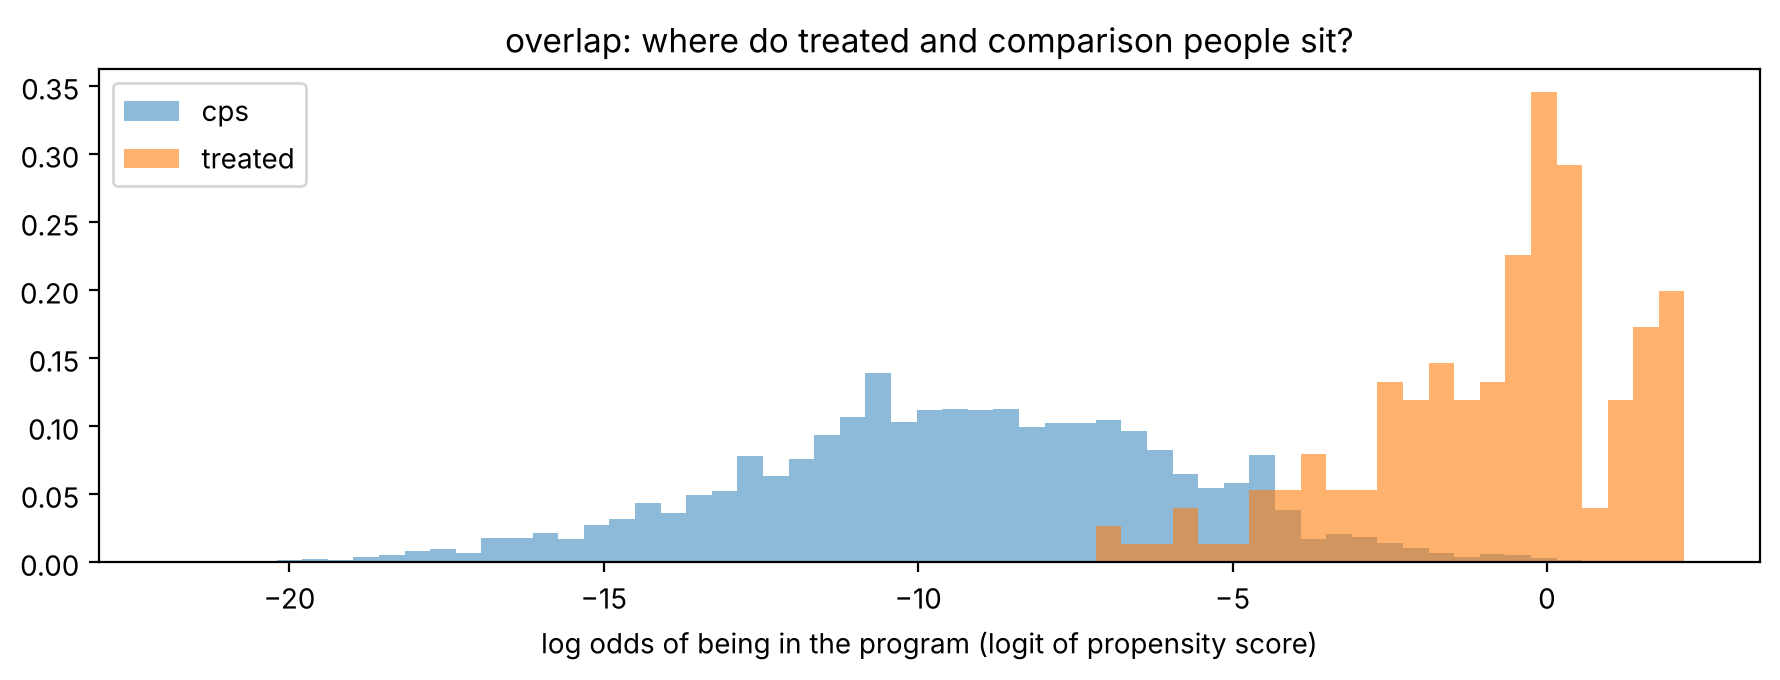

In [4]:
logitPs = np.log(observational.ps / (1 - observational.ps))
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.linspace(logitPs.min(), logitPs.max(), 60)
ax.hist(logitPs[observational.treat == 0], bins=bins, alpha=0.5, density=True, label="cps")
ax.hist(logitPs[observational.treat == 1], bins=bins, alpha=0.6, density=True, label="treated")
ax.set_xlabel("log odds of being in the program (logit of propensity score)")
ax.set_title("overlap: where do treated and comparison people sit?")
ax.legend()
plt.tight_layout()
plt.show()

This is the most important picture in the project. Most CPS people sit far to the left: the model says they had essentially **zero** chance of being in the program. They have no "twin" in the treated group, so they can't tell us anything about $Y(0)$ for participants. Regression used them anyway.

## Part C · Overlap and trimming

We keep only the **region of common support**: comparison people whose score is at least as high as the lowest treated score, and treated people whose score is no higher than the highest comparison score.

In [5]:
treatedPs = observational.loc[observational.treat == 1, "ps"]
controlPs = observational.loc[observational.treat == 0, "ps"]
lower, upper = treatedPs.min(), controlPs.max()

trimmed = observational[(observational.ps >= lower) & (observational.ps <= upper)].copy()
before = observational.treat.value_counts()
after = trimmed.treat.value_counts()
print(f"cps controls: {before[0]:,} -> {after[0]:,}   (dropped {before[0] - after[0]:,})")
print(f"treated:      {before[1]:,} -> {after[1]:,}   (dropped {before[1] - after[1]:,})")

cps controls: 15,992 -> 4,458   (dropped 11,534)
treated:      185 -> 181   (dropped 4)


About 11,500 comparison people go, because nobody in the program looked like them. A few treated people drop too, because nobody in CPS looked like *them*. That quietly changes the question: we're now estimating the effect for the treated people who have comparable controls. **Always report how many people you dropped and why.**

## Part D · Matching

For each treated person, find the comparison person with the closest propensity score (on the log-odds scale), then compare outcomes:

$$\widehat{ATT}_{match} = \frac{1}{n_1} \sum_{i: T_i = 1} \big( Y_i - Y_{j(i)} \big)$$

where $j(i)$ is $i$'s match. Choices made here:
- **1-to-1, with replacement**: a comparison person can be reused if they're the best match for several treated people
- **Caliper**: no match if the closest one is more than 0.2 standard deviations of the log-odds away (a common rule from Austin, 2011)

In [6]:
trimmed["logitPs"] = np.log(trimmed.ps / (1 - trimmed.ps))
caliper = 0.2 * trimmed.logitPs.std()

treatedRows = trimmed[trimmed.treat == 1]
controlRows = trimmed[trimmed.treat == 0]

finder = NearestNeighbors(n_neighbors=1).fit(controlRows[["logitPs"]])
distance, matchIndex = finder.kneighbors(treatedRows[["logitPs"]])
withinCaliper = distance[:, 0] <= caliper

matchedTreated = treatedRows[withinCaliper]
matchedControls = controlRows.iloc[matchIndex[withinCaliper, 0]]

attMatch = (matchedTreated.re78.to_numpy() - matchedControls.re78.to_numpy()).mean()
scoreboard["propensity score matching"] = attMatch
print(f"matched {withinCaliper.sum()} of {len(treatedRows)} treated people (caliper = {caliper:.3f})")
print(f"distinct cps people used as matches: {matchedControls.index.nunique()}")
print(f"matching ATT: ${attMatch:,.0f}")

matched 181 of 181 treated people (caliper = 0.360)
distinct cps people used as matches: 114
matching ATT: $1,618


**Did matching balance the groups?** Re-run the balance table on the matched sample. (Comparison people used twice count twice.)

In [7]:
matchedSample = pd.concat([matchedTreated, matchedControls])
pd.concat({"before (all cps)": balanceTable(observational, covariates)["smd"],
           "after matching": balanceTable(matchedSample, covariates)["smd"]}, axis=1)

,before (all cps),after matching
covariate,,
age,-0.796,-0.105
educ,-0.679,0.088
black,2.428,-0.030
hisp,-0.051,-0.023
marr,-1.233,-0.196
nodegree,0.904,-0.061
re74,-1.569,0.016
re75,-1.746,0.013
u74,1.487,0.012


The huge SMDs shrink toward zero. Any that are still above about 0.1 tell you the match isn't perfect on that variable. That's a warning to note, not a reason to hide the result.

## Part E · Inverse probability weighting (IPW)

Instead of picking matches, **reweight** every comparison person so the comparison group looks like the treated group.

- Treated people get weight 1.
- Comparison people get weight $\dfrac{e(x)}{1 - e(x)}$: the odds of being treated.

**Intuition:** a CPS person with a 1% chance of being in the program barely counts. A CPS person with a 50% chance looks just like a participant, so they count a lot. The weighted comparison mean estimates $E[Y(0) \mid T = 1]$:

$$\widehat{ATT}_{IPW} = \bar Y_{T=1} \;-\; \frac{\sum_{i:T_i=0} w_i Y_i}{\sum_{i:T_i=0} w_i}, \qquad w_i = \frac{e(X_i)}{1-e(X_i)}$$

In [8]:
trimmed["w"] = np.where(trimmed.treat == 1, 1.0, trimmed.ps / (1 - trimmed.ps))

treatedMean = trimmed.loc[trimmed.treat == 1, "re78"].mean()
weightedControlMean = np.average(trimmed.loc[trimmed.treat == 0, "re78"],
                                 weights=trimmed.loc[trimmed.treat == 0, "w"])
attIpw = treatedMean - weightedControlMean
scoreboard["inverse probability weighting"] = attIpw

controlWeights = trimmed.loc[trimmed.treat == 0, "w"]
effectiveN = controlWeights.sum() ** 2 / (controlWeights ** 2).sum()
print(f"IPW ATT: ${attIpw:,.0f}")
print(f"comparison people kept: {len(controlWeights):,}   effective sample size: {effectiveN:,.0f}")

IPW ATT: $1,719
comparison people kept: 4,458   effective sample size: 102


Look at the **effective sample size**: thousands of comparison people, but after weighting they carry the information of only about a hundred. A handful of people with high propensity scores do most of the work. That's honest. It tells you how little real comparison data exists, and it's why the uncertainty in notebook 4 is wide.

In [9]:
pd.concat({"before (all cps)": balanceTable(observational, covariates)["smd"],
           "after IPW": balanceTable(trimmed, covariates, w=trimmed.w)["smd"]}, axis=1)

,before (all cps),after IPW
covariate,,
age,-0.796,-0.108
educ,-0.679,0.026
black,2.428,-0.061
hisp,-0.051,0.036
marr,-1.233,0.052
nodegree,0.904,-0.019
re74,-1.569,0.016
re75,-1.746,0.035
u74,1.487,-0.023


## The scoreboard

                                estimate  gap_from_benchmark
benchmark (experiment)         1,794.000               0.000
naive difference              -8,498.000         -10,292.000
regression (basic)               699.000          -1,095.000
regression (rich)              1,184.000            -611.000
propensity score matching      1,618.000            -176.000
inverse probability weighting  1,719.000             -75.000


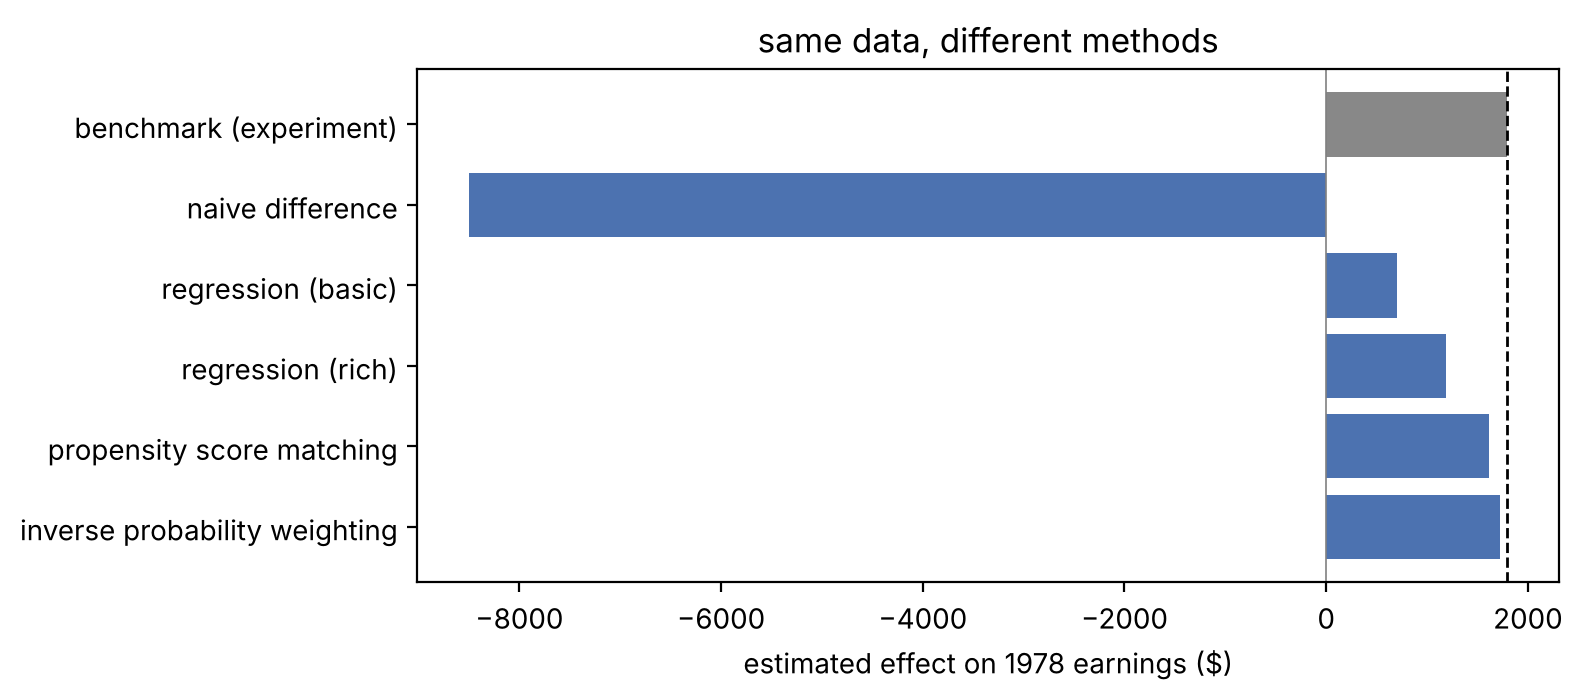

In [10]:
board = pd.Series(scoreboard, name="estimate").to_frame()
board["gap_from_benchmark"] = board["estimate"] - benchmark
print(board.round(0).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
order = board.index[::-1]
ax.barh(order, board.loc[order, "estimate"], color=["#888" if "benchmark" in k else "#4c72b0" for k in order])
ax.axvline(benchmark, color="black", ls="--", lw=1)
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("estimated effect on 1978 earnings ($)")
ax.set_title("same data, different methods")
plt.tight_layout()
plt.show()

### What the scoreboard says

- The naive comparison is useless here.
- Regression gets the sign right but stays off, because it extrapolates across groups that barely overlap.
- Matching and weighting, which first throw out comparison people with no counterpart, land close to the experimental answer.

**Don't over-celebrate.** Notebook 4 shows how much these answers move with reasonable changes to the model, and runs a test this analysis doesn't fully pass. Getting close once is not the same as being reliable.

---

### Check your understanding

1. Which of the two assumptions can you check with data, and how did you check it here?
2. Why does regression adjustment struggle on this data while matching does better?
3. In IPW, why does a comparison person with propensity 0.5 get a much bigger weight than one with 0.01?
4. Your HR model says 3,000 non-mentored employees had near-zero probability of joining the mentoring program. What should you do with them, and what should you tell your audience?

<details><summary>Answers</summary>

1. Overlap: the propensity score histogram, then trimming to common support. Unconfoundedness can't be checked. You argue for it from how people got into the program.
2. Regression fits mostly the CPS people and extrapolates to a group it barely saw. Matching and weighting only compare people who look alike.
3. Weight = odds = 0.5/0.5 = 1 vs. 0.01/0.99 ≈ 0.01. The 0.5 person looks like someone who could have been treated, so they're a better stand-in for $Y(0)$.
4. Trim them, and say so: "This estimate applies to the kinds of employees who actually join. We can't say much about people who were never likely to join."
</details>

### Interview line
> "My first check is overlap. If the comparison group has no one who looks like the participants, no model can fix that. I trim to common support, adjust with matching or weighting, and confirm the adjustment worked with a balance table before I look at the outcome."